Loading Fashion MNIST dataset...
Training samples: 5000, Testing samples: 1000

--- Training KNN with K=3 ---
Accuracy with K=3: 0.8130
Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.79      0.74       107
           1       0.94      0.96      0.95       105
           2       0.67      0.77      0.71       111
           3       0.90      0.77      0.83        93
           4       0.81      0.72      0.76       115
           5       0.97      0.78      0.87        87
           6       0.57      0.56      0.57        97
           7       0.88      0.91      0.89        95
           8       0.98      0.93      0.95        95
           9       0.83      0.96      0.89        95

    accuracy                           0.81      1000
   macro avg       0.83      0.81      0.82      1000
weighted avg       0.82      0.81      0.81      1000


--- Training KNN with K=5 ---
Accuracy with K=5: 0.8070
Classification Report:
  

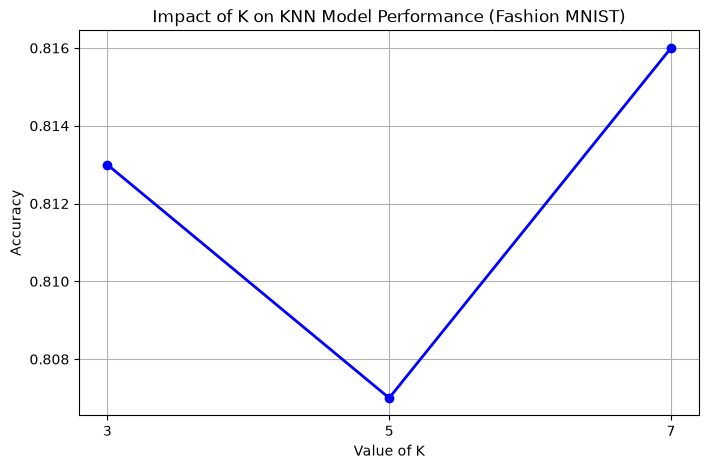

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.datasets import fashion_mnist


print("Loading Fashion MNIST dataset...")
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()


X_train = X_train.reshape((X_train.shape[0], -1)) / 255.0
X_test = X_test.reshape((X_test.shape[0], -1)) / 255.0


X_train_sub, y_train_sub = X_train[:5000], y_train[:5000]
X_test_sub, y_test_sub = X_test[:1000], y_test[:1000]

print(f"Training samples: {X_train_sub.shape[0]}, Testing samples: {X_test_sub.shape[0]}")


k_values = [3, 5, 7]
accuracies = []

for k in k_values:
    print(f"\n--- Training KNN with K={k} ---")
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_sub, y_train_sub)
    

    y_pred = knn.predict(X_test_sub)
    acc = accuracy_score(y_test_sub, y_pred)
    accuracies.append(acc)
    
    print(f"Accuracy with K={k}: {acc:.4f}")
    print("Classification Report:")
    print(classification_report(y_test_sub, y_pred))


plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b', linewidth=2)
plt.xlabel('Value of K')
plt.ylabel('Accuracy')
plt.title('Impact of K on KNN Model Performance (Fashion MNIST)')
plt.xticks(k_values)
plt.grid(True)
plt.show()